<a href="https://colab.research.google.com/github/Yesid-Valencia/Deep-Learning---Especializacion-IA/blob/main/R2-A1-S10%20Redes%20Neuronales%20V.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##REDES NEURONALES V
Red Siamesa, Embeddings y Triplet Loss con PyTorch


In [197]:
import math  # Operaciones matemáticas básicas
import random  # Generación de números pseudoaleatorios
import os  # Interacción con el sistema operativo y rutas
import itertools  # Herramientas para iteraciones eficientes
import numpy as np  # Manipulación y cálculo de arreglos numéricos
import matplotlib.pyplot as plt  # Creación de gráficos y visualizaciones
from PIL import Image, ImageDraw  # Procesamiento y dibujo sobre imágenes
import torch  # Biblioteca principal de aprendizaje profundo PyTorch
import torch.nn as nn  # Capas y módulos para construcción de redes
import torch.nn.functional as F  # Funciones de activación, pérdida y operaciones matemáticas de red
from torch.utils.data import Dataset, DataLoader  # Clases para estructurar y cargar datos

In [ ]:
SEED = 42  # Definimos una semilla global para reproducibilidad
random.seed(SEED)  # Fijamos la semilla para la librería standard 'random'
np.random.seed(SEED)  # Aseguramos consistencia en las operaciones de NumPy
torch.manual_seed(SEED)  # Configuramos la semilla para la generación de tensores de PyTorch

# Seleccionamos GPU si está disponible para acelerar el entrenamiento, de lo contrario usamos CPU
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('PyTorch:', torch.__version__)  # Mostramos la versión instalada de PyTorch
print('Dispositivo:', DEVICE)  # Confirmamos el procesador activo

PyTorch: 2.14.1+cpu
Dispositivo: cpu


In [ ]:
def synthetic_face(identity, variant, size=64):
    rng = random.Random(identity * 1000 + variant)
    img = Image.new('L', (size, size), color=230)
    d = ImageDraw.Draw(img)

    params = [
        (18, 20, 10, 42, 0),
        (16, 22, 12, 40, 1),
        (20, 18, 9, 44, 2),
        (17, 19, 13, 41, 3),
    ][identity]

    eye_dx, eye_y, eye_r, mouth_y, style = params
    jx = rng.randint(-2, 2)
    jy = rng.randint(-2, 2)

    d.ellipse(
        (10+jx, 7+jy, 54+jx, 59+jy),
        fill=185 + identity*10,
        outline=60,
        width=2
    )

    cx = 32 + jx
    ey = eye_y + jy
    for ex in (cx-eye_dx//2, cx+eye_dx//2):
        d.ellipse(
            (ex-eye_r//4, ey-eye_r//4,
             ex+eye_r//4, ey+eye_r//4),
            fill=30
        )

    d.line(
        (cx, ey+4, cx-2, ey+14, cx+2, ey+14),
        fill=70,
        width=2
    )

    if style % 2 == 0:
        d.arc(
            (20+jx, mouth_y-6+jy, 44+jx, mouth_y+8+jy),
            start=10, end=170, fill=40, width=2
        )
    else:
        d.arc(
            (20+jx, mouth_y-2+jy, 44+jx, mouth_y+12+jy),
            start=190, end=350, fill=40, width=2
        )

    if style == 1:
        d.line((18+jx, 15+jy, 46+jx, 15+jy),
               fill=40, width=3)
    if style == 2:
        d.ellipse((24+jx, 44+jy, 40+jx, 49+jy),
                  outline=40, width=2)
    if style == 3:
        d.line((15+jx, 28+jy, 49+jx, 28+jy),
               fill=90, width=1)

    arr = np.array(img, dtype=np.float32)
    noise = np.random.default_rng(
        identity*100 + variant
    ).normal(0, 3, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return arr


In [ ]:
N_ID = 4
N_PER = 12
images = []
labels = []

for ident in range(N_ID):
    for variant in range(N_PER):
        images.append(synthetic_face(ident, variant))
        labels.append(ident)

images = np.stack(images)
labels = np.array(labels)

print('Forma:', images.shape)
print('Etiquetas:', labels.shape)
print('Rango:', images.min(), images.max())


Forma: (48, 64, 64)
Etiquetas: (48,)
Rango: 20 241


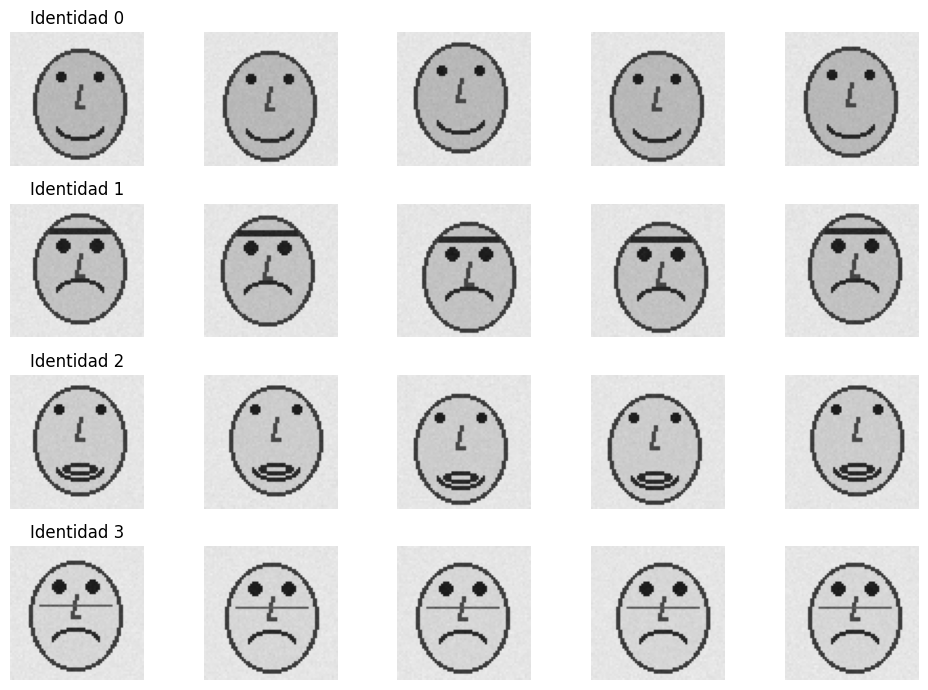

In [ ]:
fig, axes = plt.subplots(N_ID, 5, figsize=(10, 7))

for i in range(N_ID):
    idx = np.where(labels == i)[0][:5]

    for j, k in enumerate(idx):
        axes[i, j].imshow(
            images[k],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[i, j].axis('off')

        if j == 0:
            axes[i, j].set_title(f'Identidad {i}')

plt.tight_layout()
plt.show()


In [ ]:
X = torch.tensor(images, dtype=torch.float32)
X = X.unsqueeze(1) / 255.0

y = torch.tensor(labels, dtype=torch.long)

print('X:', X.shape)
print('y:', y.shape)
print('Rango X:', float(X.min()), float(X.max()))


X: torch.Size([48, 1, 64, 64])
y: torch.Size([48])
Rango X: 0.0784313753247261 0.9450980424880981


In [ ]:
class TripletFaces(Dataset):

    """Clase personalizada de Dataset para generar tripletas (Anchor, Positive, Negative)
    con el fin de entrenar la red usando la pérdida de margen (Triplet Loss)."""

    def __init__(self, X, y, triplets_per_epoch=400):
        self.X = X  # Guardamos el tensor de imágenes
        self.y = y  # Guardamos el tensor de etiquetas correspondientes
        self.n = triplets_per_epoch  # Definimos la cantidad de tripletas por época

        # Agrupamos los índices de las imágenes por clase para facilitar la selección
        self.by_class = {
            int(c): torch.where(y == c)[0].tolist()
            for c in torch.unique(y)
        }
        self.classes = list(self.by_class)  # Lista con los identificadores de clase únicos

    def __len__(self):
        # Retorna el tamaño lógico del dataset en cada época
        return self.n

    def __getitem__(self, idx):
        # 1. Seleccionamos aleatoriamente la clase del Anchor y del Positive
        a_class = random.choice(self.classes)

        # 2. Buscamos clases alternativas que no coincidan con la clase del Anchor
        other_classes = [
            c for c in self.classes
            if c != a_class
        ]
        # 3. Seleccionamos aleatoriamente una de esas clases alternativas para el Negative
        n_class = random.choice(other_classes)

        # 4. Extraemos dos imágenes distintas de la misma clase (Anchor y Positive)
        a_idx, p_idx = random.sample(
            self.by_class[a_class], 2
        )
        # 5. Extraemos una imagen de la clase diferente (Negative)
        n_idx = random.choice(
            self.by_class[n_class]
        )

        # Retornamos los tensores de imagen y sus clases asociadas
        return (
            self.X[a_idx],
            self.X[p_idx],
            self.X[n_idx],
            a_class,
            n_class
        )

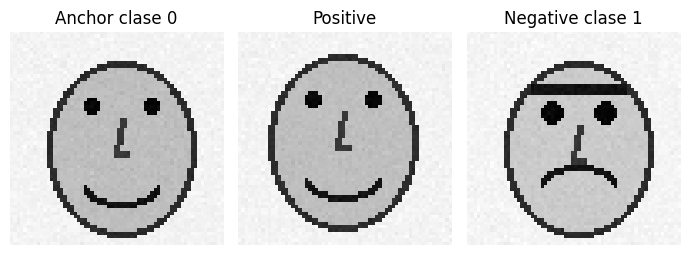

In [ ]:
trip = TripletFaces(X, y, triplets_per_epoch=400)

a, p, n, ca, cn = trip[0]

fig, ax = plt.subplots(1, 3, figsize=(7, 2.5))

for tensor_img, title, axis in [
    (a, f'Anchor clase {ca}', ax[0]),
    (p, 'Positive', ax[1]),
    (n, f'Negative clase {cn}', ax[2])
]:
    axis.imshow(tensor_img.squeeze(), cmap='gray')
    axis.set_title(title)
    axis.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
class Encoder(nn.Module):

    """Red neuronal encargada de proyectar imágenes de alta dimensión (64x64)
    a un vector de características normalizado de menor dimensión (embedding)."""

    def __init__(self, emb_dim=64):
        super().__init__()

        # Bloque extractor de características convolucional
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),  # Convolución 2D: 1 canal de entrada -> 8 de salida
            nn.ReLU(),  # Activación no lineal ReLU
            nn.MaxPool2d(2),  # Reduce el tamaño espacial a la mitad (32x32)

            nn.Conv2d(8, 16, 3, padding=1),  # Convolución 2D: 8 canales -> 16 de salida
            nn.ReLU(),  # Activación ReLU
            nn.MaxPool2d(2),  # Reduce el tamaño espacial a la mitad (16x16)

            nn.Conv2d(16, 32, 3, padding=1),  # Convolución 2D: 16 canales -> 32 de salida
            nn.ReLU(),  # Activación ReLU
            nn.AdaptiveAvgPool2d((4, 4))  # Pooling adaptativo: fuerza la salida a tamaño fijo (4x4)
        )

        # Capa completamente conectada para proyectar el resultado a la dimensión del embedding
        self.fc = nn.Linear(32 * 4 * 4, emb_dim)

    def forward(self, x):
        z = self.features(x)  # Extrae características convolucionales
        z = z.flatten(1)  # Aplana el tensor conservando la dimensión del batch
        z = self.fc(z)  # Aplica la transformación lineal hacia la dimensión final
        z = F.normalize(z, p=2, dim=1)  # Normalización L2 para proyectar sobre la hiperesfera unitaria
        return z

In [ ]:
model = Encoder(emb_dim=64).to(DEVICE)

print(model)

with torch.no_grad():
    example_embedding = model(
        X[:2].to(DEVICE)
    )

print(
    'Embedding de ejemplo:',
    example_embedding.shape
)


Encoder(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (fc): Linear(in_features=512, out_features=64, bias=True)
)
Embedding de ejemplo: torch.Size([2, 64])


In [ ]:
# Creamos el cargador de datos usando el cargador por lotes (DataLoader)
loader = DataLoader(
    trip,  # El dataset de tripletas configurado anteriormente
    batch_size=32,  # Procesamos 32 muestras simultáneamente en cada iteración
    shuffle=True  # Mezclamos los datos en cada época para evitar sesgos secuenciales
)

# Definimos la función de pérdida TripletMarginLoss
# Exige que la distancia (L2) Anchor-Negative supere a la Anchor-Positive por al menos 0.8
criterion = nn.TripletMarginLoss(
    margin=0.8,  # Margen mínimo requerido
    p=2  # Distancia euclídea convencional
)

# Configuramos el optimizador Adam con una tasa de aprendizaje de 0.001
optimizer = torch.optim.Adam(
    model.parameters(),  # Indicamos los pesos del modelo que deseamos optimizar
    lr=1e-3  # Tasa de aprendizaje (learning rate)
)

In [ ]:
losses = []

for epoch in range(18):
    model.train()
    total = 0
    count = 0

    for a, p, n, _, _ in loader:
        a = a.to(DEVICE)
        p = p.to(DEVICE)
        n = n.to(DEVICE)

        za = model(a)
        zp = model(p)
        zn = model(n)

        loss = criterion(za, zp, zn)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item() * a.size(0)
        count += a.size(0)

    mean_loss = total / count
    losses.append(mean_loss)

    if epoch in [0, 1, 2, 5, 10, 17]:
        print(
            f'Época {epoch+1:02d} | '
            f'loss={mean_loss:.4f}'
        )


Época 01 | loss=0.3981
Época 02 | loss=0.0266
Época 03 | loss=0.0024
Época 06 | loss=0.0000
Época 11 | loss=0.0001
Época 18 | loss=0.0000


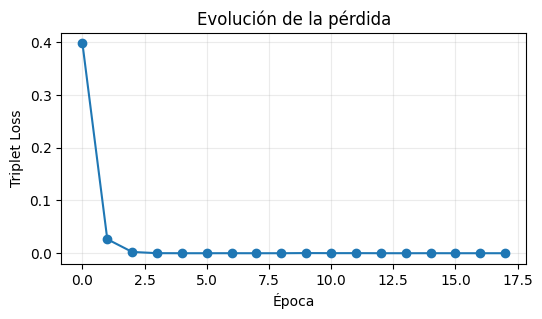

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(losses, marker='o')
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Evolución de la pérdida')
plt.grid(alpha=.25)
plt.show()


In [ ]:
model.eval()

with torch.no_grad():
    Z = model(
        X.to(DEVICE)
    ).cpu()

print('Forma de Z:', Z.shape)


Forma de Z: torch.Size([48, 64])


Distancia positiva media: 0.1275
Distancia negativa media: 1.5803


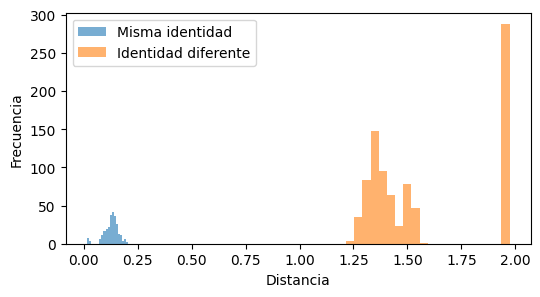

In [ ]:
pos = []
neg = []

for i in range(len(X)):
    for j in range(i + 1, len(X)):
        distance = torch.dist(
            Z[i], Z[j]
        ).item()

        if labels[i] == labels[j]:
            pos.append(distance)
        else:
            neg.append(distance)

print(
    'Distancia positiva media:',
    round(float(np.mean(pos)), 4)
)
print(
    'Distancia negativa media:',
    round(float(np.mean(neg)), 4)
)

plt.figure(figsize=(6, 3))
plt.hist(
    pos, bins=20, alpha=.6,
    label='Misma identidad'
)
plt.hist(
    neg, bins=20, alpha=.6,
    label='Identidad diferente'
)
plt.legend()
plt.xlabel('Distancia')
plt.ylabel('Frecuencia')
plt.show()


In [ ]:
refs = {
    c: np.where(labels == c)[0][0]
    for c in range(N_ID)
}

queries = [
    i for i in range(len(X))
    if i not in refs.values()
]

correct = 0

for i in queries:
    dists = {
        c: torch.dist(
            Z[i], Z[idx]
        ).item()
        for c, idx in refs.items()
    }

    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_one = correct / len(queries)

print(
    'Accuracy One-shot:',
    round(acc_one, 4),
    f'({correct}/{len(queries)})'
)


Accuracy One-shot: 1.0 (44/44)


In [ ]:
ref_ids = {
    c: np.where(labels == c)[0][:3]
    for c in range(N_ID)
}

prototypes = {}

for c, idx in ref_ids.items():
    proto = Z[idx].mean(
        0, keepdim=True
    )
    proto = F.normalize(
        proto, p=2, dim=1
    )
    prototypes[c] = proto.squeeze(0)

query_ids = [
    i for i in range(len(X))
    if all(
        i not in ids
        for ids in ref_ids.values()
    )
]

correct = 0

for i in query_ids:
    dists = {
        c: torch.dist(
            Z[i], proto
        ).item()
        for c, proto in prototypes.items()
    }

    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_few = correct / len(query_ids)

print(
    'Accuracy Few-shot:',
    round(acc_few, 4),
    f'({correct}/{len(query_ids)})'
)
print(
    'Comparación -> One-shot:',
    round(acc_one, 4),
    '| Few-shot:',
    round(acc_few, 4)
)


Accuracy Few-shot: 1.0 (36/36)
Comparación -> One-shot: 1.0 | Few-shot: 1.0


In [ ]:
threshold = (
    float(np.mean(pos)) +
    float(np.mean(neg))
) / 2

print(
    'Umbral pedagógico:',
    round(threshold, 4)
)

def verify(i, j):
    distance = torch.dist(
        Z[i], Z[j]
    ).item()

    same_identity = distance < threshold
    return distance, same_identity

same = np.where(labels == 0)[0][:2]

diff = (
    np.where(labels == 0)[0][0],
    np.where(labels == 1)[0][0]
)

for pair in [tuple(same), diff]:
    distance, ok = verify(*pair)
    result = 'MISMA' if ok else 'DIFERENTE'

    print(
        pair,
        'dist=', round(distance, 4),
        '=>', result
    )


Umbral pedagógico: 0.8539
(np.int64(0), np.int64(1)) dist= 0.17 => MISMA
(np.int64(0), np.int64(12)) dist= 1.4229 => DIFERENTE


##Preparar la carga de fotografías propias o autorizadas

In [ ]:
from pathlib import Path

def load_authorized_faces(
    root='/content/rostros',
    size=(64, 64)
):
    root = Path(root)
    imgs = []
    labs = []
    names = []

    if not root.exists():
        print('Aún no existe', root)
        return None, None, None

    persons = sorted([
        p for p in root.iterdir()
        if p.is_dir()
    ])

    for label, person in enumerate(persons):
        names.append(person.name)

        for fp in sorted(person.glob('*')):
            if fp.suffix.lower() not in {
                '.jpg', '.jpeg', '.png', '.webp'
            }:
                continue

            img = Image.open(fp)
            img = img.convert('L').resize(size)

            imgs.append(
                np.array(img, dtype=np.uint8)
            )
            labs.append(label)

    if not imgs:
        print('No se encontraron imágenes.')
        return None, None, names

    Xr = torch.tensor(
        np.stack(imgs),
        dtype=torch.float32
    ).unsqueeze(1) / 255.0

    yr = torch.tensor(
        labs,
        dtype=torch.long
    )

    print('Personas:', names)
    print('Xr:', Xr.shape, 'yr:', yr.shape)

    return Xr, yr, names



In [198]:
# Estructura sugerida:
# /content/rostros/
#   persona_01/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg
#   persona_02/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg

Xr, yr, names = load_authorized_faces(
    '/content/rostros'
)


Personas: ['persona_01', 'persona_02']
Xr: torch.Size([6, 1, 64, 64]) yr: torch.Size([6])


##Práctica complementaria con fotografías reales

In [199]:
# Validamos la existencia del modelo cargado en el espacio de nombres global
print('Modelo disponible:', 'model' in globals())

# Verificamos si la variable del procesador (CPU/GPU) está definida globalmente
print('DEVICE disponible:', 'DEVICE' in globals())

# Estructura condicional para asegurar que el entorno cuente con los recursos mínimos requeridos
if 'model' not in globals() or 'DEVICE' not in globals():
    # Mensaje de advertencia si falta alguno de los elementos clave del entrenamiento previo
    print('Debes ejecutar primero la práctica principal de Redes Neuronales V.')
else:
    # Confirmación de que el entorno está listo para procesar las imágenes reales
    print('Podemos continuar con fotografías reales.')

Modelo disponible: True
DEVICE disponible: True
Podemos continuar con fotografías reales.


In [ ]:
import os  # Interacción con funciones básicas del sistema operativo (directorios, rutas)
import shutil  # Operaciones de alto nivel con archivos (copiado, borrado recursivo)
from pathlib import Path  # Representación y manipulación de rutas del sistema orientada a objetos

import numpy as np  # Manipulación ágil y eficiente de arreglos multidimensionales de datos
import matplotlib.pyplot as plt  # Creación de gráficos y visualización de imágenes

from PIL import Image, ImageOps  # Procesamiento, ajuste de contraste, recorte y redimensionado de imágenes

import torch  # Biblioteca core del framework de aprendizaje profundo para cálculo con tensores
import torch.nn.functional as F  # Funciones matemáticas de redes como similitud de coseno o normalización

from google.colab import files  # Módulo específico de Colab que habilita la interfaz para subir archivos locales

# Confirmación interactiva que le indica al usuario que el entorno importó todas las dependencias correctamente
print('Librerías cargadas correctamente')

Librerías cargadas correctamente


In [ ]:
ruta_base = '/content/rostros'

if os.path.exists(ruta_base):
    shutil.rmtree(ruta_base)

os.makedirs('/content/rostros/persona_01', exist_ok=True)
os.makedirs('/content/rostros/persona_02', exist_ok=True)

print('Carpetas preparadas:')
print('/content/rostros/persona_01')
print('/content/rostros/persona_02')


Carpetas preparadas:
/content/rostros/persona_01
/content/rostros/persona_02


In [ ]:
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 1')

fotos_persona1 = files.upload()

if len(fotos_persona1) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona1))

for nombre, contenido in fotos_persona1.items():
    ruta = '/content/rostros/persona_01/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 1 guardadas:', len(fotos_persona1))


Seleccione EXACTAMENTE 3 fotografías de PERSONA 1


Saving Foto3.jpg to Foto3.jpg
Saving Foto2.jpg to Foto2.jpg
Saving Foto1.jpg to Foto1.jpg
Fotos de Persona 1 guardadas: 3


In [ ]:
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 2')

fotos_persona2 = files.upload()

if len(fotos_persona2) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona2))

for nombre, contenido in fotos_persona2.items():
    ruta = '/content/rostros/persona_02/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 2 guardadas:', len(fotos_persona2))


Seleccione EXACTAMENTE 3 fotografías de PERSONA 2


Saving Foto6.jpg to Foto6.jpg
Saving Foto5.jpg to Foto5.jpg
Saving Foto4.jpg to Foto4.jpg
Fotos de Persona 2 guardadas: 3


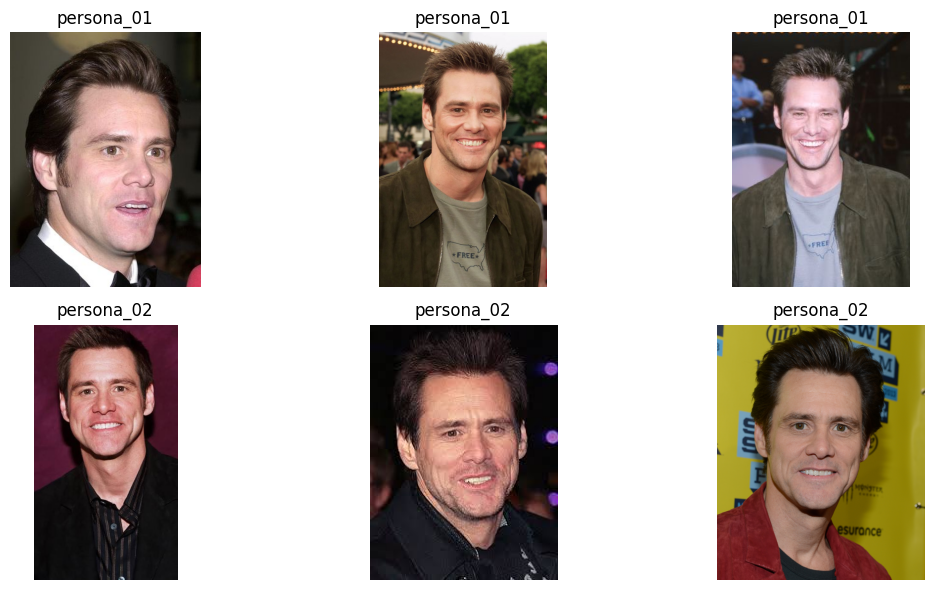

In [ ]:
# Definimos la lista con las rutas del directorio de cada una de las personas
carpetas = [
    '/content/rostros/persona_01',
    '/content/rostros/persona_02'
]

# Inicializamos la figura de matplotlib especificando las dimensiones del lienzo (ancho, alto) en pulgadas
plt.figure(figsize=(12, 6))

# Creamos una variable de control para llevar el conteo e índice de las subparcelas de visualización
posicion = 1

# Iteramos a través de cada una de las rutas de carpetas de personas
for carpeta in carpetas:
    # Extraemos el nombre final del directorio para utilizarlo como etiqueta de la identidad
    persona = os.path.basename(carpeta)

    # Listamos y ordenamos alfabéticamente los archivos contenidos en el directorio actual
    for archivo in sorted(os.listdir(carpeta)):
        # Construimos la ruta absoluta al archivo uniendo el directorio base y el nombre del archivo
        ruta = os.path.join(carpeta, archivo)

        # Cargamos la imagen desde el almacenamiento local y la forzamos al espacio de color RGB
        imagen = Image.open(ruta).convert('RGB')

        # Configuramos la cuadrícula de visualización en un formato de 2 filas por 3 columnas
        plt.subplot(2, 3, posicion)

        # Proyectamos la imagen cargada en la subparcela correspondiente
        plt.imshow(imagen)

        # Asignamos el nombre de la persona como título sobre la imagen mostrada
        plt.title(persona)

        # Ocultamos los ejes coordenados de la gráfica para mejorar la limpieza visual
        plt.axis('off')

        # Incrementamos el contador para posicionar correctamente la siguiente fotografía
        posicion += 1

# Ajustamos automáticamente la distribución de las subparcelas para evitar solapamientos
plt.tight_layout()

# Renderizamos el gráfico completo en la interfaz del notebook
plt.show()

In [ ]:
def cargar_rostros(carpeta='/content/rostros', tamano=(64, 64)):
    carpeta = Path(carpeta)

    imagenes = []
    etiquetas = []
    nombres_personas = []

    personas = sorted([p for p in carpeta.iterdir() if p.is_dir()])

    for etiqueta, persona in enumerate(personas):
        nombres_personas.append(persona.name)
        print('Leyendo:', persona.name)

        for archivo in sorted(persona.glob('*')):
            if archivo.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.webp'}:
                continue

            imagen = Image.open(archivo).convert('L')
            imagen = ImageOps.fit(imagen, tamano)
            imagen = np.array(imagen, dtype=np.uint8)

            imagenes.append(imagen)
            etiquetas.append(etiqueta)

    Xr = torch.tensor(np.stack(imagenes), dtype=torch.float32)
    Xr = Xr.unsqueeze(1) / 255.0

    yr = torch.tensor(etiquetas, dtype=torch.long)

    return Xr, yr, nombres_personas


In [ ]:
Xr, yr, nombres = cargar_rostros('/content/rostros')

print('Personas encontradas:', nombres)
print('Forma de las imágenes:', Xr.shape)
print('Etiquetas:', yr)


Leyendo: persona_01
Leyendo: persona_02
Personas encontradas: ['persona_01', 'persona_02']
Forma de las imágenes: torch.Size([6, 1, 64, 64])
Etiquetas: tensor([0, 0, 0, 1, 1, 1])


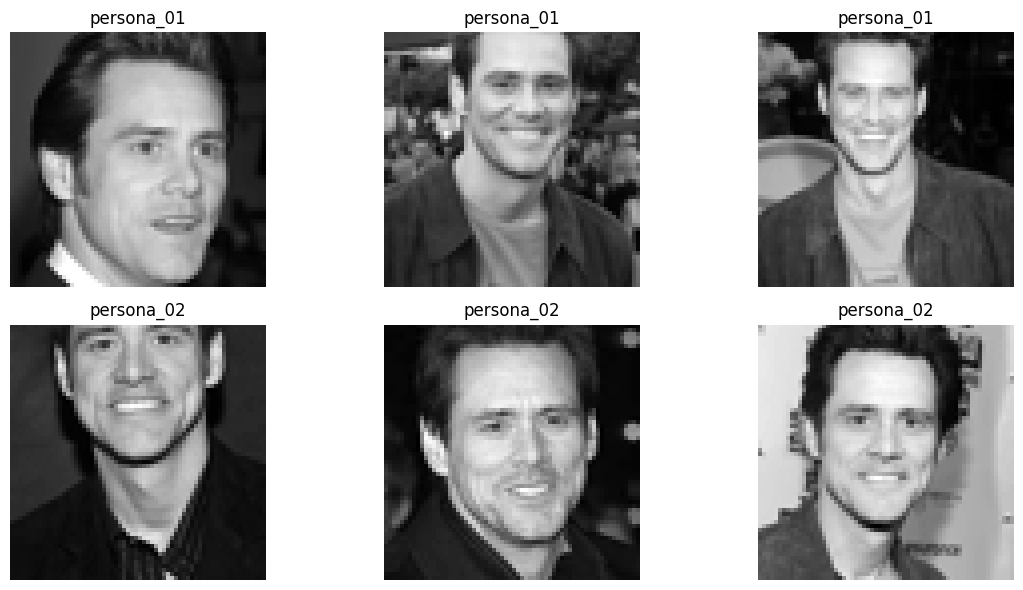

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(len(Xr)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(Xr[i].squeeze(), cmap='gray')
    plt.title(nombres[yr[i].item()])
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# 1. Extraemos la primera fotografía (índice 0) del lote para que actúe como el 'Anchor' (punto de referencia)
anchor = Xr[0]       # Representa a la Persona 1

# 2. Extraemos la segunda fotografía (índice 1) de la misma clase para que actúe como el 'Positive'
positive = Xr[1]     # Representa a la Persona 1 (misma identidad que el Anchor)

# 3. Extraemos la cuarta fotografía (índice 3), que pertenece a otra clase, para que actúe como el 'Negative'
negative = Xr[3]     # Representa a la Persona 2 (identidad distinta al Anchor)

# 4. Imprimimos en consola las dimensiones (shapes) de cada tensor para validar su formato (canales, alto, ancho)
print('Anchor:', anchor.shape)
print('Positive:', positive.shape)
print('Negative:', negative.shape)

Anchor: torch.Size([1, 64, 64])
Positive: torch.Size([1, 64, 64])
Negative: torch.Size([1, 64, 64])


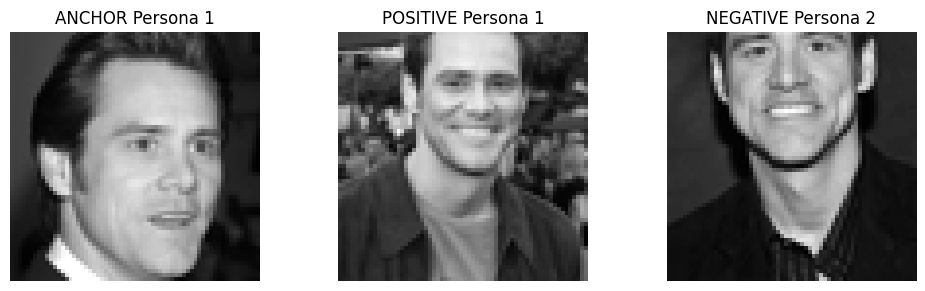

In [ ]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 3, 1)
plt.imshow(anchor.squeeze(), cmap='gray')
plt.title('ANCHOR Persona 1')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(positive.squeeze(), cmap='gray')
plt.title('POSITIVE Persona 1')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(negative.squeeze(), cmap='gray')
plt.title('NEGATIVE Persona 2')
plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# 1. Cambiamos la red neuronal al modo de evaluación para desactivar capas como Dropout o Batch Normalization si existieran
model.eval()

# 2. Desactivamos el cálculo y almacenamiento de gradientes para ahorrar memoria y acelerar la inferencia
with torch.no_grad():
    # Añadimos la dimensión del lote (batch dimension) con unsqueeze(0) y enviamos el tensor al procesador configurado (CPU o GPU)
    anchor_batch = anchor.unsqueeze(0).to(DEVICE)
    positive_batch = positive.unsqueeze(0).to(DEVICE)
    negative_batch = negative.unsqueeze(0).to(DEVICE)

    # Proyectamos las imágenes en la red (forward pass) para generar los correspondientes vectores de características (embeddings)
    embedding_anchor = model(anchor_batch)
    embedding_positive = model(positive_batch)
    embedding_negative = model(negative_batch)

# 3. Imprimimos el tamaño final de los embeddings resultantes para verificar su dimensión (debería ser de 1x64)
print('Embedding Anchor:', embedding_anchor.shape)
print('Embedding Positive:', embedding_positive.shape)
print('Embedding Negative:', embedding_negative.shape)

Embedding Anchor: torch.Size([1, 64])
Embedding Positive: torch.Size([1, 64])
Embedding Negative: torch.Size([1, 64])


In [ ]:
print('Primeros 10 valores del Anchor:')
print(embedding_anchor[0][:10])

print('Primeros 10 valores del Positive:')
print(embedding_positive[0][:10])

print('Primeros 10 valores del Negative:')
print(embedding_negative[0][:10])


Primeros 10 valores del Anchor:
tensor([-0.0140,  0.0386, -0.0507,  0.0761,  0.0864, -0.0253, -0.2400,  0.2142,
        -0.0236, -0.1705])
Primeros 10 valores del Positive:
tensor([ 0.0598,  0.1486, -0.1286, -0.1042,  0.2018, -0.0383, -0.1668,  0.2234,
         0.0548, -0.1016])
Primeros 10 valores del Negative:
tensor([ 0.0584,  0.1528, -0.1265, -0.1028,  0.1969, -0.0273, -0.1897,  0.2351,
         0.0196, -0.0857])


In [ ]:
# 1. Normalizamos el embedding del Anchor aplicando la norma L2 (p=2) a lo largo de la dimensión de características (dim=1)
embedding_anchor_norm = F.normalize(embedding_anchor, p=2, dim=1)

# 2. Normalizamos el embedding del Positive para proyectarlo también sobre la superficie de la hiperesfera unitaria
embedding_positive_norm = F.normalize(embedding_positive, p=2, dim=1)

# 3. Normalizamos el embedding del Negative garantizando la misma escala para una correcta comparación de distancias métricas
embedding_negative_norm = F.normalize(embedding_negative, p=2, dim=1)

# 4. Imprimimos un mensaje de confirmación que valide que los tensores se han reescalado con éxito
print('Embeddings normalizados correctamente')

Embeddings normalizados correctamente


In [ ]:
# 1. Calculamos la distancia euclídea (L2) entre el Anchor y el Positive, convirtiendo el tensor a un número escalar flotante de Python
distancia_AP = torch.dist(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

# 2. Calculamos la distancia euclídea (L2) entre el Anchor y el Negative para cuantificar la separación de identidades
distancia_AN = torch.dist(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

# 3. Imprimimos ambos valores en la consola redondeados a 4 decimales para evaluar cuantitativamente la métrica de similitud
print('Distancia misma persona:', round(distancia_AP, 4))
print('Distancia personas diferentes:', round(distancia_AN, 4))

Distancia misma persona: 0.7586
Distancia personas diferentes: 0.7569


In [ ]:
if distancia_AP < distancia_AN:
    print('RESULTADO:')
    print('La red acerca correctamente las imágenes de la misma persona.')
else:
    print('RESULTADO:')
    print('La red NO logró separar correctamente estas fotografías.')


RESULTADO:
La red NO logró separar correctamente estas fotografías.


In [ ]:
# 1. Calculamos la similitud coseno entre el Anchor y el Positive para evaluar la cercanía angular de sus embeddings
similitud_AP = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

# 2. Calculamos la similitud coseno entre el Anchor y el Negative para verificar la desalineación angular de vectores de distinta identidad
similitud_AN = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

# 3. Mostramos en consola los coeficientes resultantes (rango de -1 a 1) para comparar la afinidad direccional de las muestras
print('Similitud misma persona:', round(similitud_AP, 4))
print('Similitud personas diferentes:', round(similitud_AN, 4))

Similitud misma persona: 0.7122
Similitud personas diferentes: 0.7135


In [ ]:
model.eval()

with torch.no_grad():
    embeddings = model(Xr.to(DEVICE))
    embeddings = F.normalize(embeddings, p=2, dim=1)

print('Embeddings generados correctamente')
print('Tamaño:', embeddings.shape)


Embeddings generados correctamente
Tamaño: torch.Size([6, 64])


In [ ]:
indices_p1 = torch.where(yr == 0)[0]
indices_p2 = torch.where(yr == 1)[0]

print('Fotos Persona 1:', indices_p1)
print('Fotos Persona 2:', indices_p2)


Fotos Persona 1: tensor([0, 1, 2])
Fotos Persona 2: tensor([3, 4, 5])


In [ ]:

referencias_p1 = embeddings[indices_p1[:2]]

prototipo_p1 = referencias_p1.mean(
    dim=0,
    keepdim=True
)

prototipo_p1 = F.normalize(
    prototipo_p1,
    p=2,
    dim=1
)

print('Prototipo Persona 1:', prototipo_p1.shape)


Prototipo Persona 1: torch.Size([1, 64])


In [ ]:
referencias_p2 = embeddings[indices_p2[:2]]

prototipo_p2 = referencias_p2.mean(
    dim=0,
    keepdim=True
)

prototipo_p2 = F.normalize(
    prototipo_p2,
    p=2,
    dim=1
)

print('Prototipo Persona 2:', prototipo_p2.shape)


Prototipo Persona 2: torch.Size([1, 64])


In [ ]:
# 1. Extraemos el embedding de la tercera imagen de la Persona 1 y añadimos la dimensión del lote con unsqueeze(0)
consulta_p1 = embeddings[indices_p1[2]].unsqueeze(0)

# 2. Calculamos la similitud coseno entre la imagen de consulta y el prototipo promedio de la Persona 1
sim_p1_p1 = F.cosine_similarity(
    consulta_p1,
    prototipo_p1
).item()

# 3. Calculamos la similitud coseno entre la imagen de consulta y el prototipo promedio de la Persona 2
sim_p1_p2 = F.cosine_similarity(
    consulta_p1,
    prototipo_p2
).item()

# 4. Imprimimos las similitudes obtenidas para contrastar los niveles de coincidencia angular
print('FOTO REAL: Persona 1')
print('Similitud con Persona 1:', round(sim_p1_p1, 4))
print('Similitud con Persona 2:', round(sim_p1_p2, 4))

# 5. Clasificamos la imagen asignando la identidad del prototipo con el que obtuvo la mayor similitud coseno
if sim_p1_p1 > sim_p1_p2:
    prediccion_p1 = 'Persona 1'
else:
    prediccion_p1 = 'Persona 2'

# 6. Mostramos el resultado final de la predicción del sistema
print('Predicción:', prediccion_p1)

FOTO REAL: Persona 1
Similitud con Persona 1: 0.971
Similitud con Persona 2: 0.9511
Predicción: Persona 1


In [ ]:
consulta_p2 = embeddings[indices_p2[2]].unsqueeze(0)

sim_p2_p1 = F.cosine_similarity(
    consulta_p2,
    prototipo_p1
).item()

sim_p2_p2 = F.cosine_similarity(
    consulta_p2,
    prototipo_p2
).item()

print('FOTO REAL: Persona 2')
print('Similitud con Persona 1:', round(sim_p2_p1, 4))
print('Similitud con Persona 2:', round(sim_p2_p2, 4))

if sim_p2_p2 > sim_p2_p1:
    prediccion_p2 = 'Persona 2'
else:
    prediccion_p2 = 'Persona 1'

print('Predicción:', prediccion_p2)


FOTO REAL: Persona 2
Similitud con Persona 1: 0.8782
Similitud con Persona 2: 0.968
Predicción: Persona 2


In [ ]:
print('=' * 45)
print('PRUEBA FEW-SHOT')
print('=' * 45)

print('CASO 1')
print('Real: Persona 1')
print('Predicción:', prediccion_p1)
print('Resultado:', 'CORRECTO' if prediccion_p1 == 'Persona 1' else 'INCORRECTO')

print('CASO 2')
print('Real: Persona 2')
print('Predicción:', prediccion_p2)
print('Resultado:', 'CORRECTO' if prediccion_p2 == 'Persona 2' else 'INCORRECTO')


PRUEBA FEW-SHOT
CASO 1
Real: Persona 1
Predicción: Persona 1
Resultado: CORRECTO
CASO 2
Real: Persona 2
Predicción: Persona 2
Resultado: CORRECTO


In [ ]:
aciertos = 0

if prediccion_p1 == 'Persona 1':
    aciertos += 1

if prediccion_p2 == 'Persona 2':
    aciertos += 1

precision = aciertos / 2

print('Aciertos:', aciertos, 'de 2')
print('Precisión:', round(precision * 100, 2), '%')


Aciertos: 2 de 2
Precisión: 100.0 %


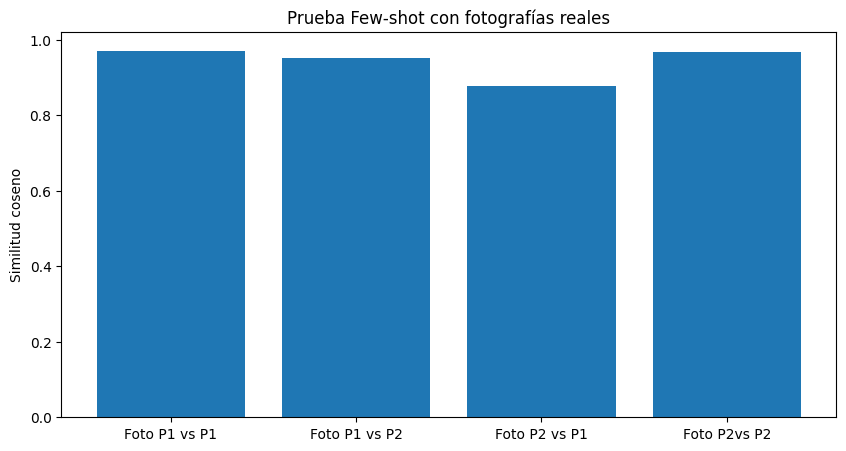

In [ ]:
valores = [
    sim_p1_p1,
    sim_p1_p2,
    sim_p2_p1,
    sim_p2_p2
]

nombres_grafica = [ 'Foto P1 vs P1',    'Foto P1 vs P2',    'Foto P2 vs P1',    'Foto P2vs P2']

plt.figure(figsize=(10, 5))
plt.bar(nombres_grafica, valores)
plt.ylabel('Similitud coseno')
plt.title('Prueba Few-shot con fotografías reales')
plt.show()


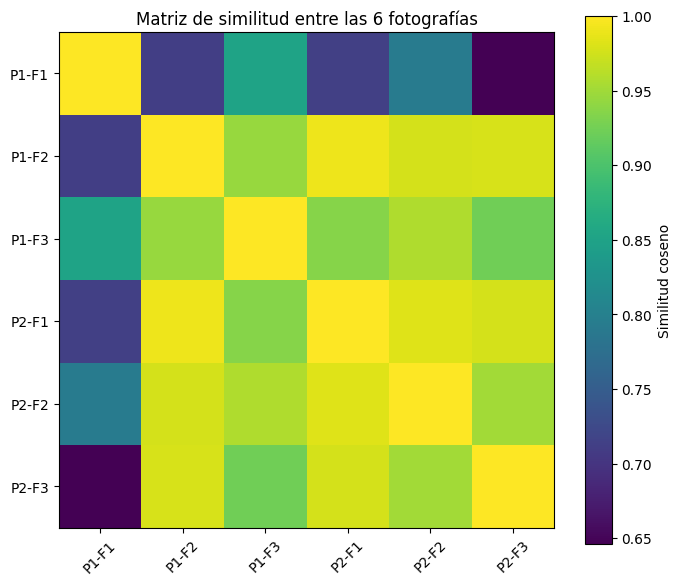

In [ ]:
matriz = embeddings @ embeddings.T
matriz_np = matriz.detach().cpu().numpy()

plt.figure(figsize=(7, 6))
plt.imshow(matriz_np)
plt.colorbar(label='Similitud coseno')

etiquetas = [
    'P1-F1', 'P1-F2', 'P1-F3',
    'P2-F1', 'P2-F2', 'P2-F3'
]

plt.xticks(range(6), etiquetas, rotation=45)
plt.yticks(range(6), etiquetas)
plt.title('Matriz de similitud entre las 6 fotografías')
plt.tight_layout()
plt.show()
